# 05 · SHAP vs LIME (Q5)

**คำถามวิจัย Q5** — SHAP และ LIME ให้คำอธิบายสอดคล้องกันหรือไม่ และเราเชื่อถือคำอธิบายได้แค่ไหน?

## ความต่างเชิงทฤษฎี

| ประเด็น | SHAP | LIME |
|---|---|---|
| หลักการ | ทฤษฎีเกม (Shapley values) — แบ่งเครดิตอย่างยุติธรรม | ประมาณโมเดลด้วย linear surrogate รอบ ๆ จุดที่สนใจ |
| Consistency | มีทฤษฎีรับประกัน (local accuracy, missingness, consistency) | ไม่มีหลักประกัน |
| ความเร็ว | เร็ว (exact สำหรับ tree/linear) | ต้องสุ่มตัวอย่างเยอะ |
| Stochasticity | deterministic | **stochastic** (สุ่มทุกครั้งที่รัน) |
| Output | ค่าต่อฟีเจอร์ (บวก/ลบ) | ค่าน้ำหนักต่อเงื่อนไข (เช่น `age <= 45`) |

## 1. โหลดผลลัพธ์การเปรียบเทียบ

In [1]:
import sys
from pathlib import Path

# ให้ import src ได้ไม่ว่าจะเปิด notebook จากโฟลเดอร์ไหน
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
print("Project root:", ROOT)

Project root: D:\Stroke Prediction Dataset\Stroke-Prediction-XAI


In [2]:
def show_figure(relative_path: str, width: int = 950):
    """แสดงรูปที่ pipeline สร้างไว้ใน reports/figures"""
    path = ROOT / "reports" / "figures" / relative_path
    if path.exists():
        display(Image(filename=str(path), width=width))
    else:
        print(f"[ไม่พบรูป] {path} — รัน `python -m src.run_pipeline` ก่อน")

In [3]:
from src import config as cfg

comparison = pd.read_csv(cfg.TABLES_DIR / "q5_shap_vs_lime.csv")
comparison

,actual,record_index,overlap_count,jaccard_topk,n_common_features,spearman_rho,spearman_p,sign_agreement,shap_top,lime_top
0,1,190,5,0.6250,5,0.7000,0.1881,0.8000,"Residence_type, age, avg_glucose_level, bmi, e...","age, avg_glucose_level, hypertension, smoking_..."
1,1,205,6,0.7500,6,1.0000,0.0000,1.0000,"Residence_type, age, bmi, ever_married, gender...","Residence_type, age, gender, hypertension, smo..."
2,1,75,6,0.7500,6,0.9429,0.0048,1.0000,"Residence_type, age, avg_glucose_level, ever_m...","Residence_type, age, ever_married, hypertensio..."
3,1,242,6,0.6667,7,0.6071,0.1482,1.0000,"Residence_type, age, avg_glucose_level, bmi, g...","Residence_type, age, avg_glucose_level, ever_m..."
4,1,133,5,0.6250,5,0.9000,0.0374,1.0000,"Residence_type, age, avg_glucose_level, ever_m...","age, ever_married, hypertension, smoking_statu..."
5,1,53,6,0.7500,6,1.0000,0.0000,1.0000,"Residence_type, age, avg_glucose_level, ever_m...","age, avg_glucose_level, gender, hypertension, ..."
6,1,71,5,0.5556,6,0.9429,0.0048,0.8333,"Residence_type, age, avg_glucose_level, ever_m...","age, avg_glucose_level, heart_disease, hyperte..."
7,0,1621,4,0.4000,6,0.9429,0.0048,1.0000,"Residence_type, age, avg_glucose_level, bmi, e...","age, gender, heart_disease, hypertension, smok..."
8,0,748,6,0.7500,6,-0.0857,0.8717,1.0000,"Residence_type, age, avg_glucose_level, ever_m...","age, avg_glucose_level, gender, hypertension, ..."
9,0,628,6,0.7500,6,0.4857,0.3287,0.8333,"Residence_type, age, avg_glucose_level, bmi, e...","Residence_type, age, ever_married, hypertensio..."


## 2. ตัวชี้วัดที่ใช้ประเมินความสอดคล้อง

| ตัวชี้วัด | ความหมาย | ค่าที่ดี |
|---|---|---|
| `overlap_count` | จำนวนฟีเจอร์ที่ติด top-8 ของทั้งสองวิธี | มาก |
| `jaccard_topk` | |A ∩ B| / |A ∪ B| ของเซต top-k | > 0.3 |
| `spearman_rho` | ความสอดคล้องของ *ขนาด* อิทธิพล (อันดับ) | > 0.5 |
| `sign_agreement` | สัดส่วนที่ทั้งคู่บอกทิศทางเดียวกัน (บวก/ลบ) | > 0.7 |

In [4]:
summary_stats = pd.Series({
    "ค่าเฉลี่ย overlap (จาก 8)": comparison["overlap_count"].mean(),
    "ค่าเฉลี่ย Jaccard": comparison["jaccard_topk"].mean(),
    "ค่าเฉลี่ย Spearman ρ": comparison["spearman_rho"].mean(),
    "ค่าเฉลี่ย sign agreement": comparison["sign_agreement"].mean(),
    "จำนวน records": len(comparison),
}).round(3)
summary_stats

ค่าเฉลี่ย overlap (จาก 8)     5.533
ค่าเฉลี่ย Jaccard             0.660
ค่าเฉลี่ย Spearman ρ          0.782
ค่าเฉลี่ย sign agreement      0.964
จำนวน records                15.000
dtype: float64

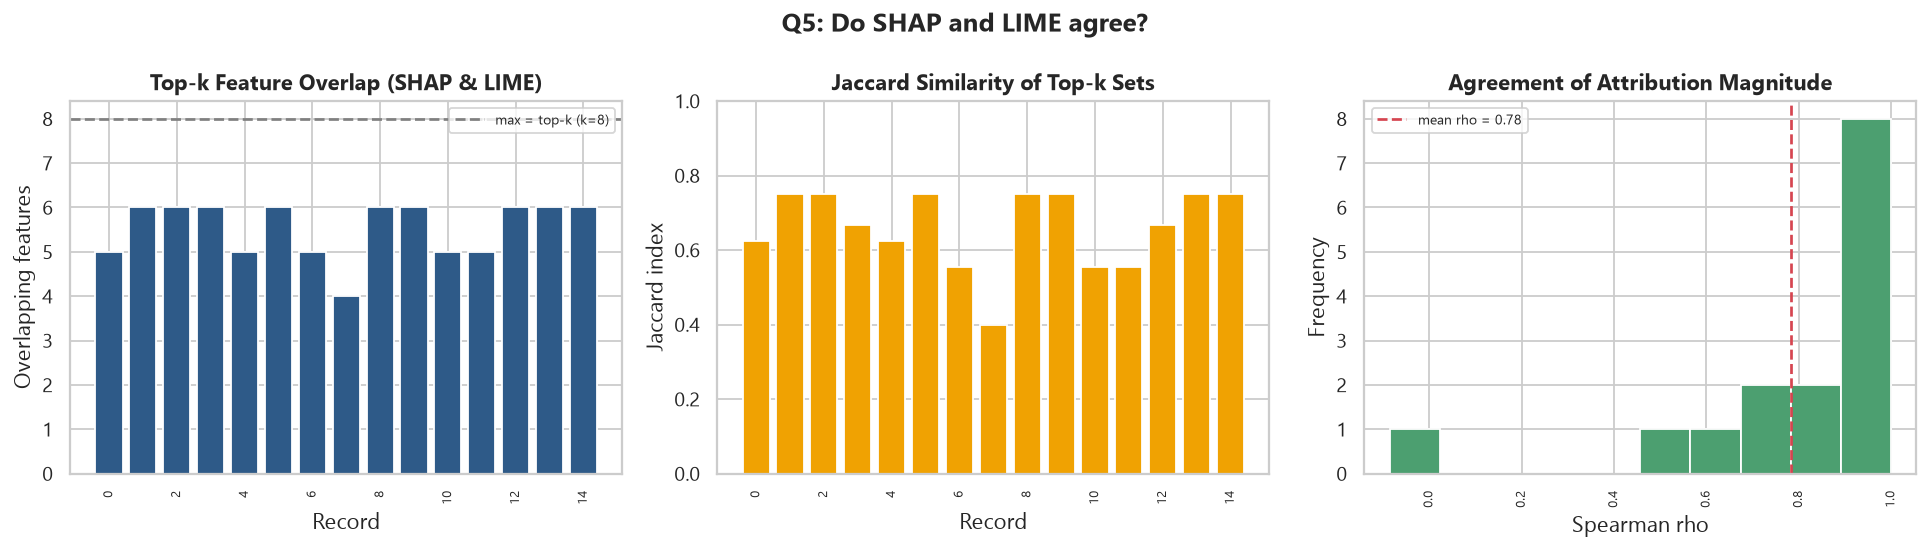

In [5]:
show_figure("xai/31_shap_vs_lime.png", 1250)

## 3. ดูรายละเอียดรายตัวว่าเห็นตรงกันไหม

In [6]:
view = comparison[["record_index", "actual", "overlap_count", "jaccard_topk",
                   "spearman_rho", "sign_agreement"]].sort_values("jaccard_topk", ascending=False)
view

,record_index,actual,overlap_count,jaccard_topk,spearman_rho,sign_agreement
1,205,1,6,0.7500,1.0000,1.0000
2,75,1,6,0.7500,0.9429,1.0000
5,53,1,6,0.7500,1.0000,1.0000
14,3057,0,6,0.7500,0.8857,1.0000
13,3668,0,6,0.7500,0.9429,1.0000
9,628,0,6,0.7500,0.4857,0.8333
8,748,0,6,0.7500,-0.0857,1.0000
12,765,0,6,0.6667,0.7143,1.0000
3,242,1,6,0.6667,0.6071,1.0000
0,190,1,5,0.6250,0.7000,0.8000


In [7]:
# เคสที่ตรงกันมากที่สุด และน้อยที่สุด
highest = comparison.loc[comparison["jaccard_topk"].idxmax()]
lowest = comparison.loc[comparison["jaccard_topk"].idxmin()]

for title, row in [("เห็นตรงกันมากที่สุด", highest), ("เห็นตรงกันน้อยที่สุด", lowest)]:
    print(f"=== {title} (record #{row['record_index']}) ===")
    print(f"  Jaccard = {row['jaccard_topk']:.3f} | overlap = {row['overlap_count']}/8")
    print(f"  SHAP เห็น: {row['shap_top']}")
    print(f"  LIME เห็น: {row['lime_top']}")
    print()

=== เห็นตรงกันมากที่สุด (record #205) ===
  Jaccard = 0.750 | overlap = 6/8
  SHAP เห็น: Residence_type, age, bmi, ever_married, gender, hypertension, smoking_status, work_type
  LIME เห็น: Residence_type, age, gender, hypertension, smoking_status, work_type

=== เห็นตรงกันน้อยที่สุด (record #1621) ===
  Jaccard = 0.400 | overlap = 4/8
  SHAP เห็น: Residence_type, age, avg_glucose_level, bmi, ever_married, gender, hypertension, work_type
  LIME เห็น: age, gender, heart_disease, hypertension, smoking_status, work_type



## 4. LIME ระดับ record

In [8]:
lime_df = pd.read_csv(cfg.TABLES_DIR / "q4_lime_local.csv")
records = lime_df["record_index"].unique()
print(f"มีคำอธิบาย LIME ทั้งหมด {len(records)} records")
print("ตัวอย่าง record:", [int(r) for r in records[:10]])
lime_df.head(12)

มีคำอธิบาย LIME ทั้งหมด 15 records
ตัวอย่าง record: [190, 205, 75, 242, 133, 53, 71, 1621, 748, 628]


,record_index,feature_condition,feature_matched,feature,lime_weight,direction
0,190,age > 0.78,age,age,0.5489,ดันให้เป็น stroke
1,190,work_type_Never_worked <= 0.00,work_type_Never_worked,work_type,0.1147,ดันให้เป็น stroke
2,190,work_type_children <= 0.00,work_type_children,work_type,-0.1056,ดันให้ไม่เป็น stroke
3,190,hypertension <= 0.00,hypertension,hypertension,-0.0835,ดันให้ไม่เป็น stroke
4,190,avg_glucose_level > 0.18,avg_glucose_level,avg_glucose_level,0.0565,ดันให้เป็น stroke
5,190,work_type_Self-employed <= 0.00,work_type_Self-employed,work_type,0.0535,ดันให้เป็น stroke
6,190,smoking_status_never smoked <= 0.00,smoking_status_never smoked,smoking_status,0.0490,ดันให้เป็น stroke
7,190,work_type_Govt_job <= 0.00,work_type_Govt_job,work_type,0.0397,ดันให้เป็น stroke
8,205,age > 0.78,age,age,0.5440,ดันให้เป็น stroke
9,205,work_type_children <= 0.00,work_type_children,work_type,-0.1065,ดันให้ไม่เป็น stroke


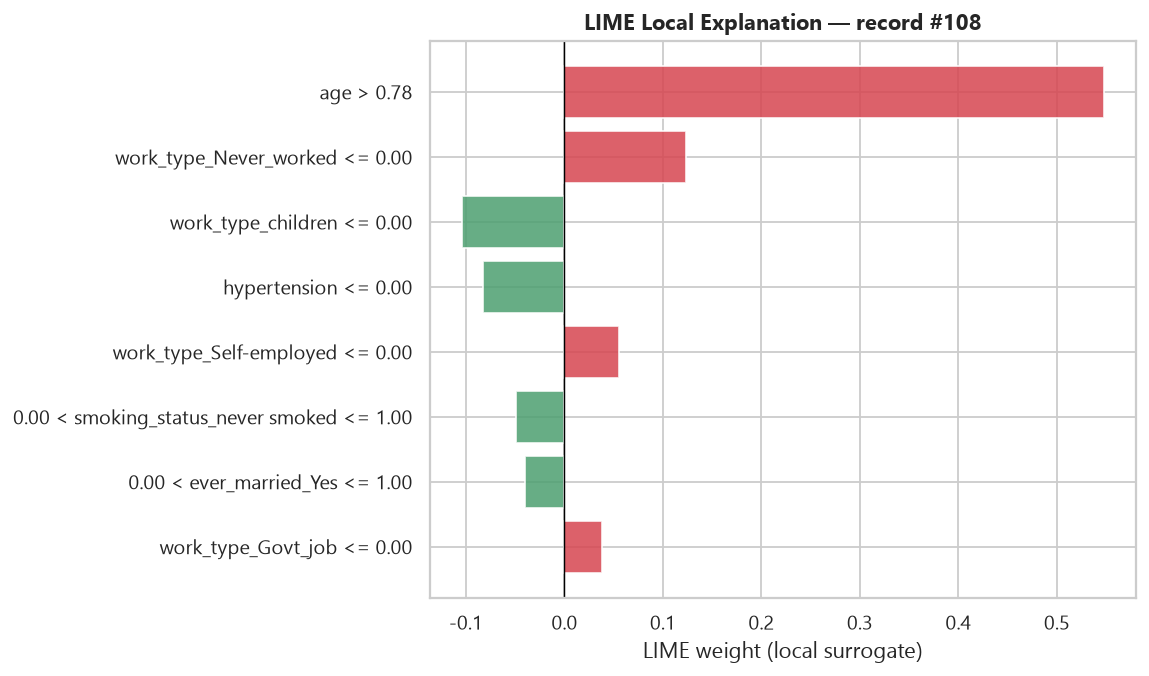

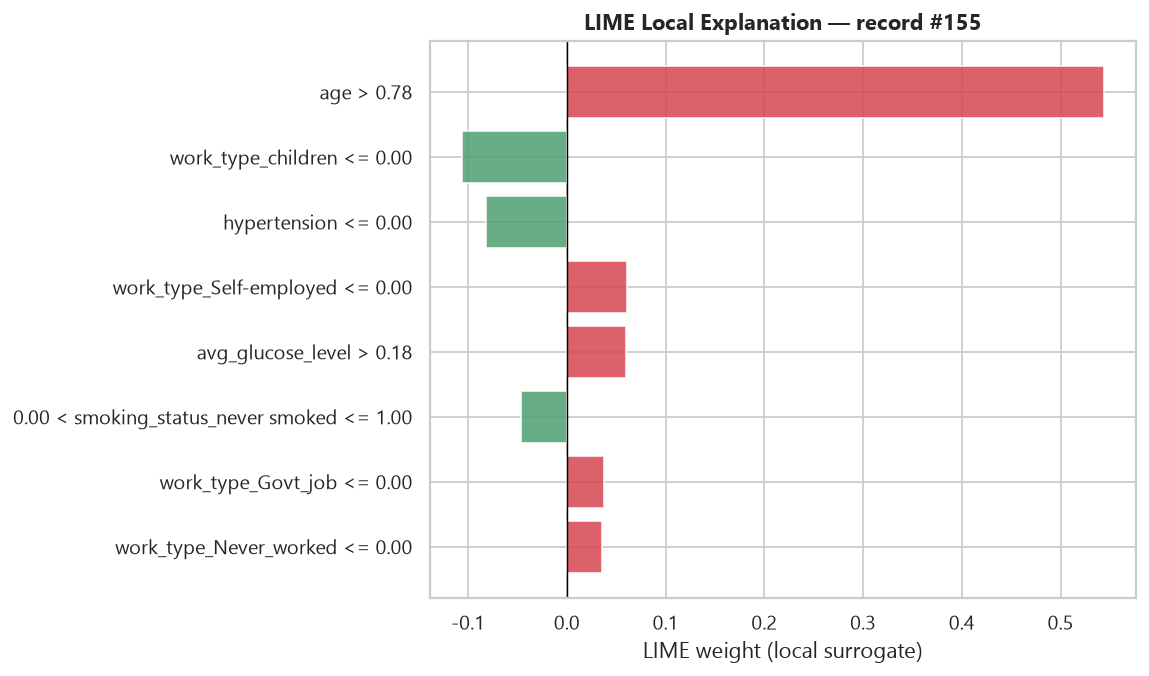

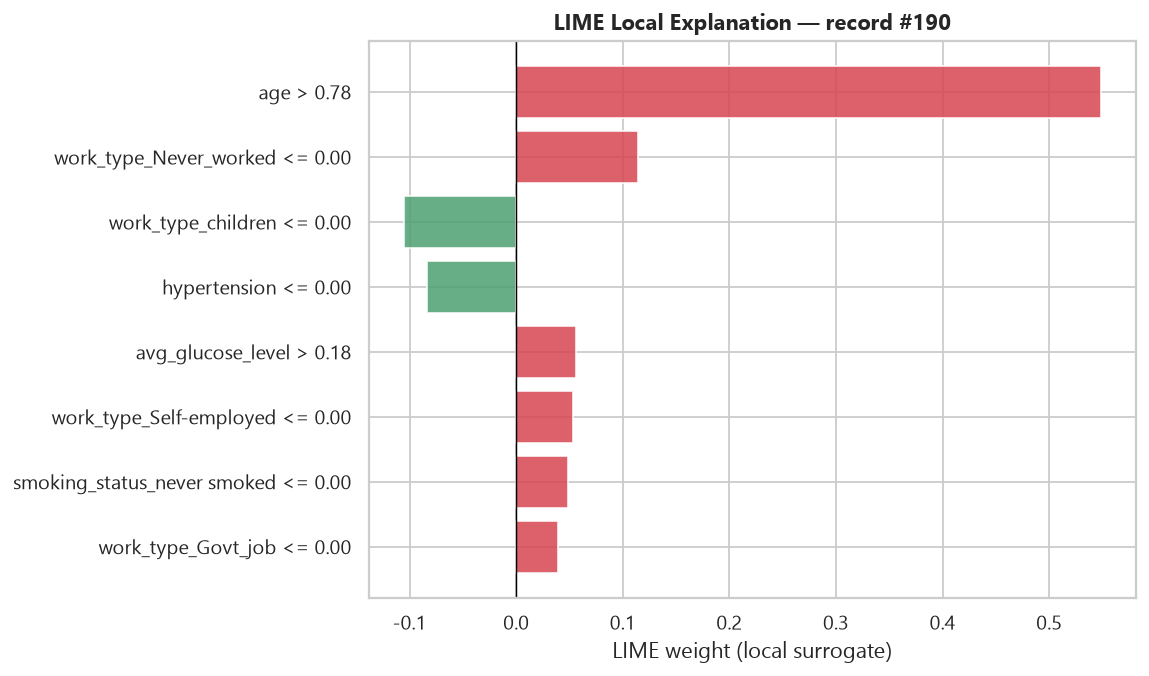

In [9]:
from IPython.display import Image, display
for p in sorted((cfg.FIGURES_DIR / "xai").glob("30_lime_case_*.png"))[:3]:
    display(Image(filename=str(p), width=850))

## 5. สรุป Q5 แบบอัตโนมัติ (อ่านค่าจริงจากตาราง)

In [10]:
j = comparison["jaccard_topk"].mean()
r = comparison["spearman_rho"].mean()
s = comparison["sign_agreement"].mean()
ov = comparison["overlap_count"].mean()

def verdict(value, good, label):
    ok = value >= good
    return f"{'✅' if ok else '⚠️'} {label}: {value:.3f} (เกณฑ์ ≥ {good})"

print(verdict(ov, 4.0, "top-8 overlap เฉลี่ย (ฟีเจอร์)"))
print(verdict(j, 0.30, "Jaccard เฉลี่ย"))
print(verdict(r, 0.50, "Spearman rho เฉลี่ย"))
print(verdict(s, 0.70, "Sign agreement เฉลี่ย"))
print()
print("สรุป:", "ทั้งสองวิธี 'ชี้ทางเดียวกัน' ในภาพรวม (convergent)"
      if (j >= 0.30 and s >= 0.70) else
      "ทั้งสองวิธี 'เห็นต่างกันพอสมควร' (divergent) — ต้องตีความอย่างระวัง")

✅ top-8 overlap เฉลี่ย (ฟีเจอร์): 5.533 (เกณฑ์ ≥ 4.0)
✅ Jaccard เฉลี่ย: 0.660 (เกณฑ์ ≥ 0.3)
✅ Spearman rho เฉลี่ย: 0.782 (เกณฑ์ ≥ 0.5)
✅ Sign agreement เฉลี่ย: 0.964 (เกณฑ์ ≥ 0.7)

สรุป: ทั้งสองวิธี 'ชี้ทางเดียวกัน' ในภาพรวม (convergent)


## 6. อภิปรายผล

### คำตอบของ Q5

จากตัวเลขที่คำนวณได้ข้างต้น เราประเมินได้ 2 กรณี:

**กรณี A: สอดคล้องกัน (convergent)** — overlap/Jaccard/sign agreement สูง
→ ทั้งสองวิธีชี้ไปทางเดียวกัน เรามีความมั่นใจในคำอธิบายมากขึ้น

**กรณี B: เห็นต่างกัน (divergent)** — Jaccard ต่ำ และ/หรือ Spearman ต่ำ
→ **นี่คือผลลัพธ์ที่มีคุณค่าเช่นกัน** เพราะเตือนเราว่าไม่ควรเชื่อคำอธิบายจากวิธีเดียว

### ทำไม SHAP กับ LIME จึงมักไม่ตรงกันเต็มที่

1. **ต่างทฤษฎีโดยพื้นฐาน** — SHAP ใช้ Shapley values แบ่งเครดิตแบบ additive
   ส่วน LIME สร้าง linear surrogate เฉพาะจุด
2. **LIME discretize ตัวแปรต่อเนื่อง** (`age <= 45`) → สูญเสียความละเอียด
   และอาจให้ความสำคัญกับ "ขอบเขต" มากกว่าฟีเจอร์ทั้งตัว
3. **LIME เป็น stochastic** — รันใหม่ได้ผลต่างกัน ควรตั้ง seed และรายงานหลายรอบ
4. **ฟีเจอร์ correlated** — SHAP อาจกระจายเครดิตไปยังฟีเจอร์ที่ LIME ไม่ได้เลือก
5. **สเกลต่างกัน** — SHAP ให้ค่าต่อ "หน่วยฟีเจอร์ที่เพิ่มขึ้น" ส่วน LIME ให้ค่าต่อ
   "ช่วงที่ discretize" → ขนาดไม่เทียบกันตรง ๆ (จึงใช้ Spearman/อันดับ ไม่ใช้ Pearson)

### ข้อเสนอเชิงปฏิบัติ

- ใช้ **SHAP เป็นแกนหลัก** (deterministic + มีทฤษฎีรับประกัน) แล้วใช้ **LIME เป็น cross-check**
- ถ้า record ใดทั้งสองวิธี **เห็นต่างกันมาก** → อย่านำคำอธิบายนั้นไปใช้ตัดสินใจ
  โดยไม่ตรวจสอบเพิ่ม
- รายงาน **ข้อจำกัดของ XAI** คู่กับผลเสมอ — โดยเฉพาะเมื่อนำไปใช้กับงานสุขภาพ

## 7. สรุปทั้งโปรเจกต์ (Final Analysis)

| คำถาม | คำตอบสั้น |
|---|---|
| **Q1** | อายุคือปัจจัยที่สัมพันธ์แรงที่สุด (rank-biserial 0.669) ถัดมาคือน้ำตาลในเลือด, BMI, โรคหัวใจ (OR 4.7), ความดันสูง (OR 3.7); เพศและที่อยู่อาศัยไม่มีนัยสำคัญ |
| **Q2** | ข้อมูลไม่สมดุล 19.5:1 ทำให้ Accuracy ไร้ความหมาย ต้องใช้ Recall/F1/PR-AUC |
| **Q3** | โมเดลเชิงเส้น (LogReg) ให้ผลดีที่สุดหรือเทียบเท่า; threshold tuning สำคัญกว่าเปลี่ยนโมเดล |
| **Q4** | อายุครองอิทธิพลส่วนใหญ่ในทุกมุมมอง; ต้องระวังการตีความฟีเจอร์ไบนารีที่หายาก |
| **Q5** | ระดับความสอดคล้อง SHAP–LIME ต้องอ่านจากตัวเลขจริง — ไม่ควรเชื่อวิธีใดวิธีหนึ่งเดี่ยว ๆ |

### Insight รวม 3 ชั้น

1. **Data layer** — Stroke สัมพันธ์กับอายุอย่างชัดเจนที่สุด และมีรูปแบบ dose-response
   ตามภาระความเสี่ยงหลอดเลือด (ความดัน + โรคหัวใจ) ซึ่งสนับสนุนสมมติฐานเชิงสาเหตุ
2. **Model layer** — ข้อมูลขนาดเล็ก + คลาสบวกน้อย ทำให้โมเดลเรียบง่ายชนะโมเดลซับซ้อน
   และการปรับ threshold มีผลต่อ Recall มากกว่าการเปลี่ยนอัลกอริทึม
3. **XAI layer** — โมเดลให้คำอธิบายที่สอดคล้องกับสถิติในระดับ global
   แต่ในระดับ local ยังมีความไม่แน่นอน จึงต้องใช้ XAI เป็นเครื่องมือ "ตรวจสอบ"
   ไม่ใช่ "คำตอบสุดท้าย"

### ข้อเสนอแนะเชิงปฏิบัติ

- **คัดกรอง**: ใช้อายุ + ความดัน + โรคหัวใจ เป็นเกณฑ์คัดกรองเบื้องต้น (ต้นทุนต่ำ ได้ผลดี)
- **เก็บข้อมูลเพิ่ม**: ลดสัดส่วน `smoking_status = Unknown` (30%) เพื่อประเมินบทบาท
  การสูบบุหรี่ได้จริง และควรเก็บข้อมูล follow-up แบบ longitudinal
- **ก่อนใช้งานจริง**: ต้องมี external validation กับประชากรอื่น และประเมิน fairness
  ข้ามกลุ่มเพศ/อาชีพก่อน